# Ejercicio 6.3b — Análisis de la efectividad de metáforas visuales (versión mejorada y extendida)

| | |
|---|---|
| **Curso** | Interacción Hombre-Computador (202W0606) · Semestre 2026-2 · Laboratorio 6 |
| **Docente** | Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU) |
| **Equipo** | Equipo A — Arboleda Sánchez, Ericka Sofía · Cabrejos Palomino, Christian Daniel · Ccoicca Fernández, Adrián · Cerna Sifuentes, Augusto Nicolás · Grijalva De La Cruz, Rony Smith · Martines Cancho, Josué · Postigo Vega, Diana Carolina · Siesquen Torres, Katherine Lizbeth · Tecsi Alanoca, Jean Carlo · Tonconi Isidro, María Sunori · Villegas Niño, Marco Antonio |
| **Universidad** | Universidad Nacional Mayor de San Marcos · FISI |
| **Fecha** | Lima, 16 de octubre de 2026 |

**Base:** notebook del docente `ejercicio_6_3_analisis_metaforas.ipynb`. Se conserva su flujo y se marcan con ✏️ las
mejoras y extensiones del equipo.

**Datos:** 30 registros reales (5 participantes × 6 tareas) registrados por el equipo con el Ejercicio 6.3 el
16/10/2026: tiempo en tarea (`performance.now()`), clics en el área de la tarea y éxito. Los registros se incrustan en
la celda de carga para que **Entorno de ejecución → Ejecutar todas** funcione sin subir archivos.

**Diseño del estudio:** intra-sujeto (medidas repetidas). Cada participante usó los tres estilos en dos tipos de tarea;
por eso las pruebas de comparación deben ser para muestras relacionadas (✏️ Friedman y Wilcoxon), no para muestras
independientes.

# Ejercicio 6.3b — Análisis de Efectividad de Metáforas Visuales

**Curso:** IHC — Interacción Hombre-Computador (UNMSM, 2026-2) · Semana 06

**Objetivo:** Analizar los datos de interacción recopilados en el Ejercicio 6.3
(medición en el navegador) para comparar la efectividad de tres estilos de
metáfora visual: **esqueumórfico**, **plano** y **neumórfico**.

**Métricas analizadas:**
- **Tiempo en tarea** (*time on task*) — eficiencia
- **Número de clics** — esfuerzo de interacción
- **Tasa de éxito** — eficacia

**Fuente de datos:** Archivo `resultados_metaforas_semana06.csv` exportado
desde el Ejercicio 6.3 (medición real en el navegador con `performance.now()`).

## 1. Librerías y estilo de las gráficas

Celda 1 del docente. ✏️ Se agregan `numpy`, `scipy.stats` y `statsmodels` (incluidos en Colab) para las pruebas
estadísticas, y el tema oscuro se reemplaza por uno claro y sobrio, legible al imprimir el informe.

In [1]:
# =========================================================
# Celda 1 — Importación de librerías y estilo (docente + ✏️ equipo)
# =========================================================
import io, os, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from statistics import mean, median, stdev
from scipy import stats                                  # ✏️ pruebas estadísticas
from statsmodels.stats.anova import AnovaRM              # ✏️ ANOVA de medidas repetidas
warnings.filterwarnings("ignore", category=UserWarning)

# ✏️ Tema claro y sobrio (para impresión); el docente usaba fondo oscuro #0F172A
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#333333",
    "axes.labelcolor": "#111111", "text.color": "#111111", "xtick.color": "#333333",
    "ytick.color": "#333333", "grid.color": "#DDDDDD", "font.family": "sans-serif",
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})
ORDEN = ["Esqueumórfico", "Plano", "Neumórfico"]
COLORES = {"Esqueumórfico": "#3A3A3A", "Plano": "#6E8FB5", "Neumórfico": "#B5B5B5"}
os.makedirs("figuras", exist_ok=True)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Carga de los datos reales

El docente pedía subir el CSV con `files.upload()`, lo que detiene «Ejecutar todas». ✏️ Ahora los 30 registros
consolidados (`resultados_6_3_consolidado.csv`, Paso 3) están incrustados en la celda. La opción de subir un CSV
nuevo se conserva comentada.

In [2]:
# =========================================================
# Celda 2 — Carga del CSV (✏️ datos reales incrustados)
# Fuente: 5 archivos resultados_metaforas_p1..p5.csv del Ejercicio 6.3
# =========================================================
CSV_REAL = """participante,tarea,estilo,tipo_tarea,descripcion,tiempo_ms,tiempo_s,clics,exito,fecha_lima,archivo
p1,1,Esqueumórfico,Interruptor (toggle),Activar interruptor,1432,1.432,1,1,2026-10-16 16:32:02,resultados_metaforas_p1.csv
p1,2,Plano,Interruptor (toggle),Activar interruptor,2323,2.323,1,1,2026-10-16 16:32:05,resultados_metaforas_p1.csv
p1,3,Neumórfico,Interruptor (toggle),Activar interruptor,1905,1.905,1,1,2026-10-16 16:32:08,resultados_metaforas_p1.csv
p1,4,Esqueumórfico,Botón Enviar,Presionar botón Enviar,872,0.872,1,1,2026-10-16 16:32:10,resultados_metaforas_p1.csv
p1,5,Plano,Botón Enviar,Presionar botón Enviar,1427,1.427,1,1,2026-10-16 16:32:12,resultados_metaforas_p1.csv
p1,6,Neumórfico,Botón Enviar,Presionar botón Enviar,666,0.666,1,1,2026-10-16 16:32:14,resultados_metaforas_p1.csv
p2,1,Esqueumórfico,Interruptor (toggle),Activar interruptor,552,0.552,1,1,2026-10-16 16:33:33,resultados_metaforas_p2.csv
p2,2,Plano,Interruptor (toggle),Activar interruptor,420,0.42,1,1,2026-10-16 16:33:34,resultados_metaforas_p2.csv
p2,3,Neumórfico,Interruptor (toggle),Activar interruptor,364,0.364,1,1,2026-10-16 16:33:35,resultados_metaforas_p2.csv
p2,4,Esqueumórfico,Botón Enviar,Presionar botón Enviar,414,0.414,1,1,2026-10-16 16:33:36,resultados_metaforas_p2.csv
p2,5,Plano,Botón Enviar,Presionar botón Enviar,329,0.329,1,1,2026-10-16 16:33:37,resultados_metaforas_p2.csv
p2,6,Neumórfico,Botón Enviar,Presionar botón Enviar,472,0.472,1,1,2026-10-16 16:33:38,resultados_metaforas_p2.csv
p3,1,Esqueumórfico,Interruptor (toggle),Activar interruptor,522,0.522,1,1,2026-10-16 16:34:11,resultados_metaforas_p3.csv
p3,2,Plano,Interruptor (toggle),Activar interruptor,531,0.531,1,1,2026-10-16 16:34:12,resultados_metaforas_p3.csv
p3,3,Neumórfico,Interruptor (toggle),Activar interruptor,1021,1.021,1,1,2026-10-16 16:34:14,resultados_metaforas_p3.csv
p3,4,Esqueumórfico,Botón Enviar,Presionar botón Enviar,470,0.47,1,1,2026-10-16 16:34:15,resultados_metaforas_p3.csv
p3,5,Plano,Botón Enviar,Presionar botón Enviar,779,0.779,1,1,2026-10-16 16:34:16,resultados_metaforas_p3.csv
p3,6,Neumórfico,Botón Enviar,Presionar botón Enviar,495,0.495,1,1,2026-10-16 16:34:17,resultados_metaforas_p3.csv
p4,1,Esqueumórfico,Interruptor (toggle),Activar interruptor,426,0.426,1,1,2026-10-16 16:34:40,resultados_metaforas_p4.csv
p4,2,Plano,Interruptor (toggle),Activar interruptor,682,0.682,1,1,2026-10-16 16:34:42,resultados_metaforas_p4.csv
p4,3,Neumórfico,Interruptor (toggle),Activar interruptor,472,0.472,1,1,2026-10-16 16:34:42,resultados_metaforas_p4.csv
p4,4,Esqueumórfico,Botón Enviar,Presionar botón Enviar,824,0.824,1,1,2026-10-16 16:34:44,resultados_metaforas_p4.csv
p4,5,Plano,Botón Enviar,Presionar botón Enviar,1012,1.012,1,1,2026-10-16 16:34:45,resultados_metaforas_p4.csv
p4,6,Neumórfico,Botón Enviar,Presionar botón Enviar,659,0.659,1,1,2026-10-16 16:34:47,resultados_metaforas_p4.csv
p5,1,Esqueumórfico,Interruptor (toggle),Activar interruptor,602,0.602,1,1,2026-10-16 16:35:09,resultados_metaforas_p5.csv
p5,2,Plano,Interruptor (toggle),Activar interruptor,388,0.388,1,1,2026-10-16 16:35:10,resultados_metaforas_p5.csv
p5,3,Neumórfico,Interruptor (toggle),Activar interruptor,375,0.375,1,1,2026-10-16 16:35:11,resultados_metaforas_p5.csv
p5,4,Esqueumórfico,Botón Enviar,Presionar botón Enviar,380,0.38,1,1,2026-10-16 16:35:11,resultados_metaforas_p5.csv
p5,5,Plano,Botón Enviar,Presionar botón Enviar,388,0.388,1,1,2026-10-16 16:35:12,resultados_metaforas_p5.csv
p5,6,Neumórfico,Botón Enviar,Presionar botón Enviar,406,0.406,1,1,2026-10-16 16:35:13,resultados_metaforas_p5.csv"""
df = pd.read_csv(io.StringIO(CSV_REAL))

# Opción del docente: subir otro CSV desde el disco (descomentar en Colab)
# from google.colab import files
# subido = files.upload()
# df = pd.read_csv(list(subido.keys())[0])

df["estilo"] = pd.Categorical(df["estilo"], categories=ORDEN, ordered=True)
print(f"Registros: {len(df)} · Participantes: {df['participante'].nunique()} · Columnas: {list(df.columns)}")
df.head(8)

Registros: 30 · Participantes: 5 · Columnas: ['participante', 'tarea', 'estilo', 'tipo_tarea', 'descripcion', 'tiempo_ms', 'tiempo_s', 'clics', 'exito', 'fecha_lima', 'archivo']


,participante,tarea,estilo,tipo_tarea,descripcion,tiempo_ms,tiempo_s,clics,exito,fecha_lima,archivo
0,p1,1,Esqueumórfico,Interruptor (toggle),Activar interruptor,1432,1.432,1,1,2026-10-16 16:32:02,resultados_metaforas_p1.csv
1,p1,2,Plano,Interruptor (toggle),Activar interruptor,2323,2.323,1,1,2026-10-16 16:32:05,resultados_metaforas_p1.csv
2,p1,3,Neumórfico,Interruptor (toggle),Activar interruptor,1905,1.905,1,1,2026-10-16 16:32:08,resultados_metaforas_p1.csv
3,p1,4,Esqueumórfico,Botón Enviar,Presionar botón Enviar,872,0.872,1,1,2026-10-16 16:32:10,resultados_metaforas_p1.csv
4,p1,5,Plano,Botón Enviar,Presionar botón Enviar,1427,1.427,1,1,2026-10-16 16:32:12,resultados_metaforas_p1.csv
5,p1,6,Neumórfico,Botón Enviar,Presionar botón Enviar,666,0.666,1,1,2026-10-16 16:32:14,resultados_metaforas_p1.csv
6,p2,1,Esqueumórfico,Interruptor (toggle),Activar interruptor,552,0.552,1,1,2026-10-16 16:33:33,resultados_metaforas_p2.csv
7,p2,2,Plano,Interruptor (toggle),Activar interruptor,420,0.420,1,1,2026-10-16 16:33:34,resultados_metaforas_p2.csv


## 3. ✏️ Validación de los datos

Antes de analizar se comprueba que no falten valores, que cada participante tenga sus 6 tareas y que los rangos sean
válidos. Se revisa también la variabilidad de clics y éxito: si no varían, no pueden diferenciar estilos.

In [3]:
# =========================================================
# ✏️ Celda 3 — Calidad de los datos
# =========================================================
print("Valores faltantes por columna:", df.isna().sum().to_dict())
print("Tareas por participante:", df.groupby("participante")["tarea"].count().to_dict())
print("Diseño completo (cada participante × estilo × tarea):",
      df.groupby(["participante", "estilo", "tipo_tarea"], observed=True).size().eq(1).all())
print(f"Tiempo: mín. {df.tiempo_ms.min()} ms · máx. {df.tiempo_ms.max()} ms")
print("Valores distintos de clics:", sorted(df.clics.unique()), "· de éxito:", sorted(df.exito.unique()))
if df.clics.nunique() == 1 and df.exito.nunique() == 1:
    print("→ Efecto techo: todos los registros tienen el mismo número de clics y éxito; solo el tiempo discrimina.")

Valores faltantes por columna: {'participante': 0, 'tarea': 0, 'estilo': 0, 'tipo_tarea': 0, 'descripcion': 0, 'tiempo_ms': 0, 'tiempo_s': 0, 'clics': 0, 'exito': 0, 'fecha_lima': 0, 'archivo': 0}
Tareas por participante: {'p1': 6, 'p2': 6, 'p3': 6, 'p4': 6, 'p5': 6}
Diseño completo (cada participante × estilo × tarea): True
Tiempo: mín. 329 ms · máx. 2323 ms
Valores distintos de clics: [np.int64(1)] · de éxito: [np.int64(1)]
→ Efecto techo: todos los registros tienen el mismo número de clics y éxito; solo el tiempo discrimina.


## 4. Estadísticas descriptivas por estilo

Celda 3 del docente (media, mediana, clics y tasa de éxito). ✏️ Se añaden desviación estándar, mínimo, máximo,
coeficiente de variación e intervalo de confianza del 95 % de la media (distribución *t*).

In [4]:
# =========================================================
# Celda 4 — Resumen por estilo (docente) + ✏️ dispersión e IC 95 %
# =========================================================
def ic95(x):
    x = np.asarray(x, dtype=float)
    m, se = x.mean(), stats.sem(x)
    h = se * stats.t.ppf(0.975, len(x) - 1)
    return m - h, m + h

resumen = df.groupby("estilo", observed=True).agg(
    n=("tiempo_ms", "size"),
    tiempo_medio_ms=("tiempo_ms", "mean"),
    tiempo_mediana_ms=("tiempo_ms", "median"),
    tiempo_de_ms=("tiempo_ms", "std"),
    tiempo_min_ms=("tiempo_ms", "min"),
    tiempo_max_ms=("tiempo_ms", "max"),
    clics_medio=("clics", "mean"),
    tasa_exito=("exito", "mean"),
)
resumen["cv_pct"] = resumen["tiempo_de_ms"] / resumen["tiempo_medio_ms"] * 100
resumen[["ic95_inf_ms", "ic95_sup_ms"]] = [ic95(df.loc[df.estilo == e, "tiempo_ms"]) for e in resumen.index]
resumen["tasa_exito_pct"] = resumen["tasa_exito"] * 100
resumen = resumen.round(1)
print("Resumen estadístico por estilo de metáfora visual:")
resumen

Resumen estadístico por estilo de metáfora visual:


,n,tiempo_medio_ms,tiempo_mediana_ms,tiempo_de_ms,tiempo_min_ms,tiempo_max_ms,clics_medio,tasa_exito,cv_pct,ic95_inf_ms,ic95_sup_ms,tasa_exito_pct
estilo,,,,,,,,,,,,
Esqueumórfico,10,649.4,537.0,321.5,380,1432,1.0,1.0,49.5,419.4,879.4,100.0
Plano,10,827.9,606.5,627.4,329,2323,1.0,1.0,75.8,379.1,1276.7,100.0
Neumórfico,10,683.5,483.5,472.1,364,1905,1.0,1.0,69.1,345.8,1021.2,100.0


### 4.1 ✏️ Por tipo de tarea y por participante

La media global puede ocultar diferencias entre tareas o el peso de un participante atípico.

In [5]:
# =========================================================
# ✏️ Celda 5 — Resumen por tipo de tarea × estilo y por participante
# =========================================================
por_tarea = df.pivot_table(index="tipo_tarea", columns="estilo", values="tiempo_ms",
                           aggfunc=["mean", "median"], observed=True).round(1)
por_participante = df.pivot_table(index="participante", columns="estilo", values="tiempo_ms",
                                  aggfunc="mean", observed=True).round(1)
por_participante["media_global"] = df.groupby("participante")["tiempo_ms"].mean().round(1)
z = (por_participante["media_global"] - por_participante["media_global"].mean()) / por_participante["media_global"].std()
por_participante["z_media"] = z.round(2)
display(por_tarea)
display(por_participante)
atipico = por_participante.index[por_participante["z_media"].abs() > 1.5].tolist()
print("Participantes con media alejada (|z| > 1.5):", atipico or "ninguno")

mean                          median         \
estilo               Esqueumórfico  Plano Neumórfico Esqueumórfico  Plano   
tipo_tarea                                                                  
Botón Enviar                 592.0  787.0      539.6         470.0  779.0   
Interruptor (toggle)         706.8  868.8      827.4         552.0  531.0   

                                 
estilo               Neumórfico  
tipo_tarea                       
Botón Enviar              495.0  
Interruptor (toggle)      472.0

estilo,Esqueumórfico,Plano,Neumórfico,media_global,z_media
participante,,,,,
p1,1152.0,1875.0,1285.5,1437.5,1.72
p2,483.0,374.5,418.0,425.2,-0.71
p3,496.0,655.0,758.0,636.3,-0.20
p4,625.0,847.0,565.5,679.2,-0.10
p5,491.0,388.0,390.5,423.2,-0.71


Participantes con media alejada (|z| > 1.5): ['p1']


## 5. Gráficos del docente: tiempo medio y clics medios por estilo

Celdas 4 y 5 del docente. ✏️ Se agregan barras de error con el IC 95 % para mostrar la incertidumbre de cada media.

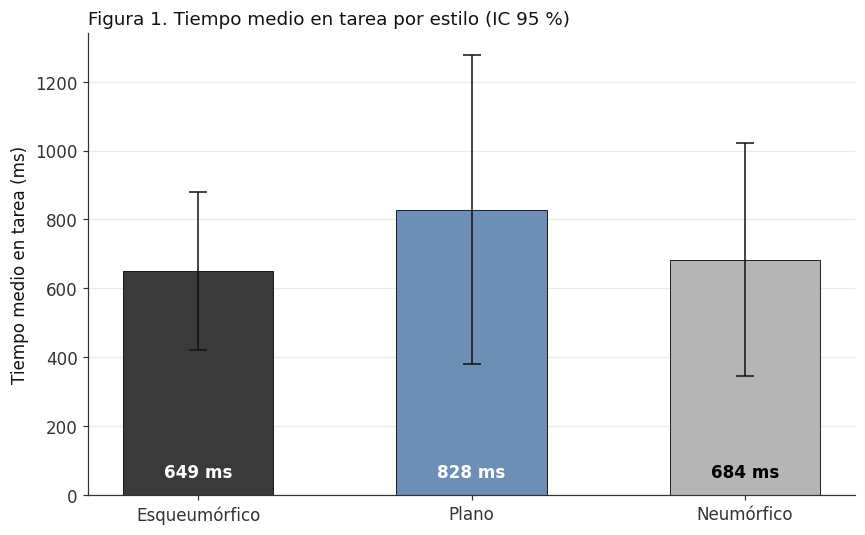

In [6]:
# =========================================================
# Celda 6 — Tiempo medio por estilo con IC 95 % (docente + ✏️ barras de error)
# =========================================================
fig, ax = plt.subplots(figsize=(8, 5))
estilos = resumen.index.tolist()
tiempos = resumen["tiempo_medio_ms"].tolist()
err = [np.array(tiempos) - resumen["ic95_inf_ms"].values, resumen["ic95_sup_ms"].values - np.array(tiempos)]
bars = ax.bar(estilos, tiempos, color=[COLORES[e] for e in estilos], edgecolor="#111111", linewidth=0.6,
              width=0.55, yerr=err, capsize=6, error_kw={"elinewidth": 1, "ecolor": "#111111"})
for bar, val in zip(bars, tiempos):
    ax.text(bar.get_x() + bar.get_width() / 2, 40, f"{val:.0f} ms", ha="center", va="bottom",
            fontweight="bold", color="white" if bar.get_facecolor()[0] < 0.6 else "black")
ax.set_axisbelow(True)
ax.set_ylabel("Tiempo medio en tarea (ms)")
ax.set_title("Figura 1. Tiempo medio en tarea por estilo (IC 95 %)", loc="left", fontsize=12)
ax.grid(axis="y", alpha=0.6)
plt.tight_layout(); plt.savefig("figuras/fig1_tiempo_medio_ic95.png", dpi=200, bbox_inches="tight"); plt.show()

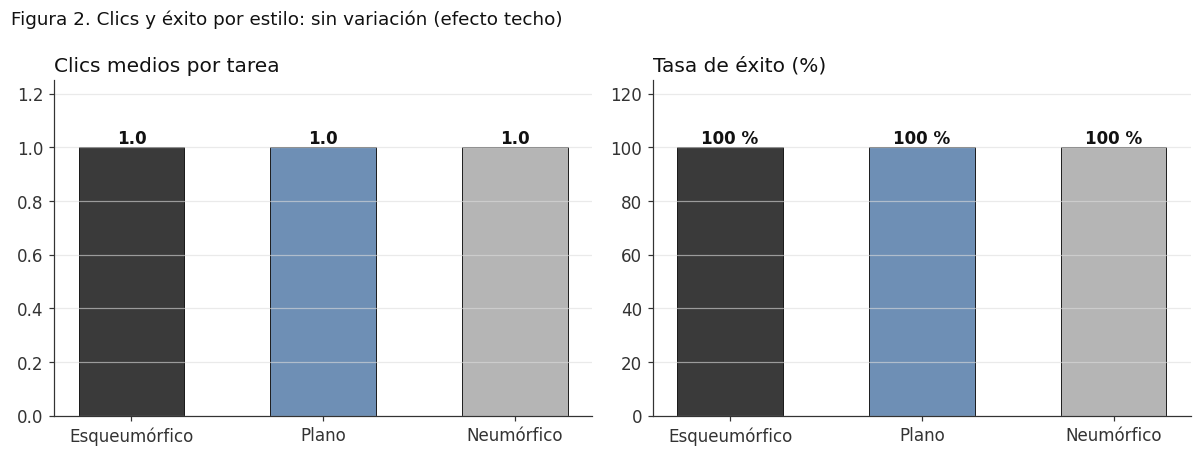

In [7]:
# =========================================================
# Celda 7 — Clics medios y tasa de éxito por estilo (docente + ✏️ éxito)
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, col, titulo, fmt in [(axes[0], "clics_medio", "Clics medios por tarea", "{:.1f}"),
                             (axes[1], "tasa_exito_pct", "Tasa de éxito (%)", "{:.0f} %")]:
    vals = resumen[col].tolist()
    b = ax.bar(estilos, vals, color=[COLORES[e] for e in estilos], edgecolor="#111111", linewidth=0.6, width=0.55)
    for bar, v in zip(b, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontweight="bold")
    ax.set_title(titulo, loc="left"); ax.set_ylim(0, max(vals) * 1.25); ax.grid(axis="y", alpha=0.6)
fig.suptitle("Figura 2. Clics y éxito por estilo: sin variación (efecto techo)", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.savefig("figuras/fig2_clics_exito.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. ✏️ Distribución y efecto de cada participante

Las medias se ven muy afectadas por valores extremos. El diagrama de caja muestra la mediana y la dispersión, y el
gráfico por participante muestra si las diferencias son consistentes dentro de cada persona (lo que importa en un
diseño intra-sujeto).

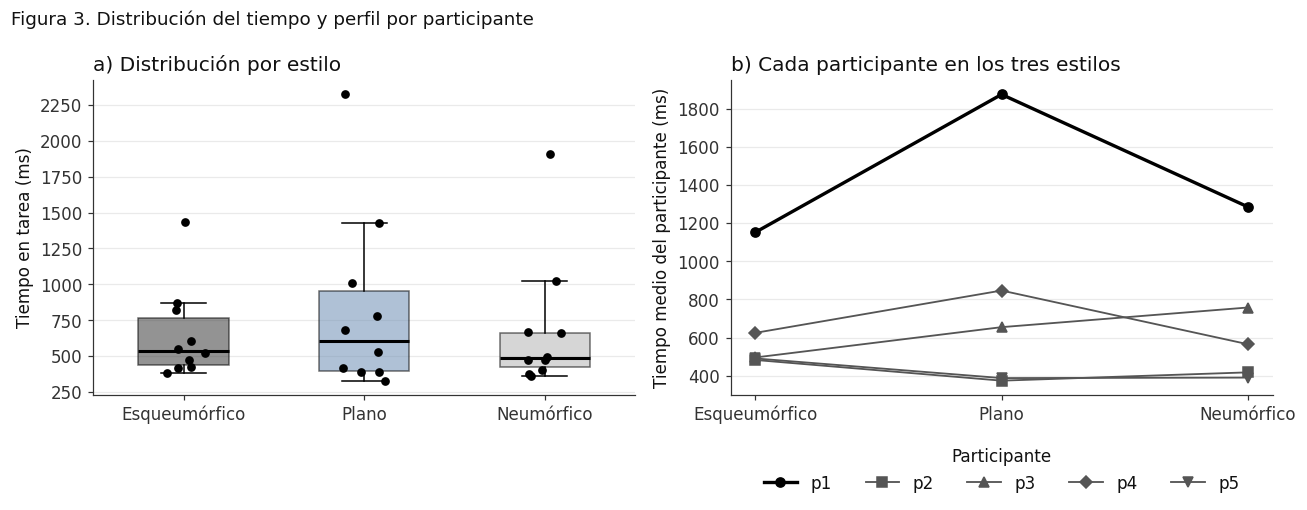

In [8]:
# =========================================================
# ✏️ Celda 8 — Diagrama de caja con puntos y gráfico por participante
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
datos = [df.loc[df.estilo == e, "tiempo_ms"].values for e in ORDEN]
bp = axes[0].boxplot(datos, tick_labels=ORDEN, patch_artist=True, widths=0.5, showfliers=False,
                     medianprops={"color": "black", "linewidth": 2})  # los puntos individuales se dibujan aparte
for caja, e in zip(bp["boxes"], ORDEN):
    caja.set_facecolor(COLORES[e]); caja.set_alpha(0.55)
rng = np.random.default_rng(6)
for i, e in enumerate(ORDEN, 1):
    sub = df[df.estilo == e]
    axes[0].scatter(i + rng.uniform(-0.12, 0.12, len(sub)), sub.tiempo_ms, s=22, color="black", zorder=3,
                    marker="o")
axes[0].set_ylabel("Tiempo en tarea (ms)"); axes[0].set_title("a) Distribución por estilo", loc="left")
axes[0].grid(axis="y", alpha=0.6)

marcas = dict(zip(sorted(df.participante.unique()), ["o", "s", "^", "D", "v"]))
for p, sub in df.groupby("participante"):
    m = sub.groupby("estilo", observed=True)["tiempo_ms"].mean().reindex(ORDEN)
    axes[1].plot(ORDEN, m.values, marker=marcas[p], color="#555555" if p != "p1" else "black",
                 linewidth=2.2 if p == "p1" else 1.2, label=p)
axes[1].set_ylabel("Tiempo medio del participante (ms)")
axes[1].set_title("b) Cada participante en los tres estilos", loc="left")
axes[1].legend(title="Participante", frameon=False, ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
axes[1].grid(axis="y", alpha=0.6)
fig.suptitle("Figura 3. Distribución del tiempo y perfil por participante", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.savefig("figuras/fig3_caja_y_participantes.png", dpi=200, bbox_inches="tight"); plt.show()

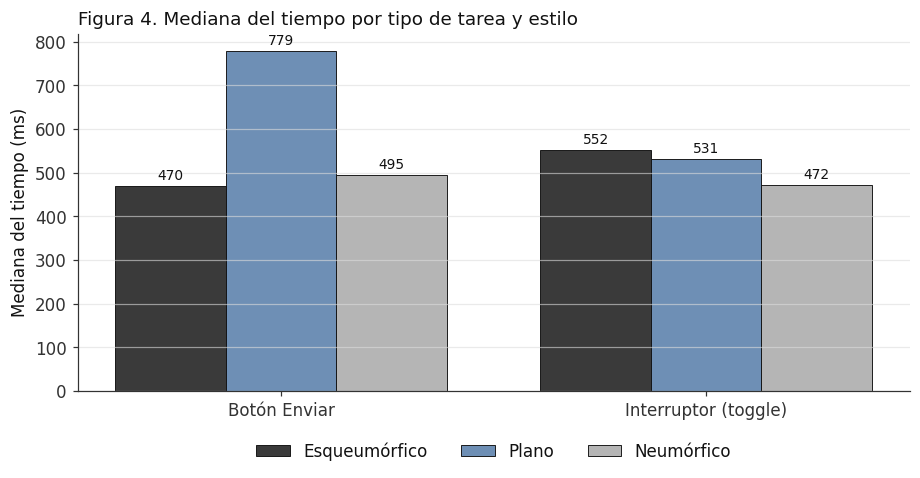

In [9]:
# =========================================================
# ✏️ Celda 9 — Tiempo por tipo de tarea y estilo (mediana)
# =========================================================
med = df.pivot_table(index="tipo_tarea", columns="estilo", values="tiempo_ms", aggfunc="median", observed=True)[ORDEN]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
x = np.arange(len(med.index)); w = 0.26
for i, e in enumerate(ORDEN):
    b = ax.bar(x + (i - 1) * w, med[e], w, label=e, color=COLORES[e], edgecolor="#111111", linewidth=0.6)
    ax.bar_label(b, fmt="%.0f", fontsize=9, padding=2)
ax.set_xticks(x, med.index); ax.set_ylabel("Mediana del tiempo (ms)")
ax.set_title("Figura 4. Mediana del tiempo por tipo de tarea y estilo", loc="left", fontsize=12)
ax.legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.1)); ax.grid(axis="y", alpha=0.6)
plt.tight_layout(); plt.savefig("figuras/fig4_mediana_tarea_estilo.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. ✏️ Pruebas estadísticas para medidas repetidas

El docente sugiere ANOVA o Kruskal-Wallis «en un estudio con 5+ participantes». Como cada participante usó los tres
estilos, las observaciones **no son independientes**; las pruebas adecuadas son:

- **Shapiro-Wilk** para ver si el tiempo se distribuye normalmente (decide entre pruebas paramétricas y no paramétricas).
- **Friedman** (no paramétrica, medidas repetidas) con **W de Kendall** como tamaño del efecto: sobre 5 bloques
  (participante, promedio de las dos tareas) y sobre 10 bloques (participante × tipo de tarea).
- **Wilcoxon de rangos con signo** por pares, con corrección de **Holm** por comparaciones múltiples.
- **ANOVA de medidas repetidas** (estilo × tipo de tarea) sobre el logaritmo del tiempo, que corrige la asimetría.
- **Kruskal-Wallis** solo como referencia, para mostrar qué pasaría si se ignorara el diseño intra-sujeto.

Nivel de significación: α = 0,05.

In [10]:
# =========================================================
# ✏️ Celda 10 — Normalidad (Shapiro-Wilk) del tiempo y del log-tiempo
# =========================================================
filas = []
for e in ORDEN:
    x = df.loc[df.estilo == e, "tiempo_ms"]
    w1, p1 = stats.shapiro(x); w2, p2 = stats.shapiro(np.log(x))
    filas.append({"estilo": e, "W_tiempo": w1, "p_tiempo": p1, "W_log": w2, "p_log": p2})
normalidad = pd.DataFrame(filas).set_index("estilo").round(3)
display(normalidad)
no_normales = normalidad.index[normalidad.p_tiempo < 0.05].tolist()
print("Estilos sin normalidad en el tiempo (p < 0,05):", no_normales or "ninguno",
      "→ se priorizan pruebas no paramétricas." if no_normales else "")

,W_tiempo,p_tiempo,W_log,p_log
estilo,,,,
Esqueumórfico,0.789,0.011,0.901,0.224
Plano,0.787,0.010,0.920,0.357
Neumórfico,0.690,0.001,0.846,0.052


Estilos sin normalidad en el tiempo (p < 0,05): ['Esqueumórfico', 'Plano', 'Neumórfico'] → se priorizan pruebas no paramétricas.


In [11]:
# =========================================================
# ✏️ Celda 11 — Friedman + W de Kendall (5 y 10 bloques)
# =========================================================
def friedman(tabla, nombre):
    chi2, p = stats.friedmanchisquare(*[tabla[e] for e in ORDEN])
    n, k = tabla.shape
    w = chi2 / (n * (k - 1))
    rangos = tabla[ORDEN].rank(axis=1).mean().round(2).to_dict()
    return {"análisis": nombre, "bloques": n, "chi2": round(chi2, 3), "gl": k - 1, "p": round(p, 4),
            "W_Kendall": round(w, 3), "rango_medio": rangos}

bloques5 = df.pivot_table(index="participante", columns="estilo", values="tiempo_ms", aggfunc="mean", observed=True)[ORDEN]
bloques10 = df.pivot_table(index=["participante", "tipo_tarea"], columns="estilo", values="tiempo_ms", observed=True)[ORDEN]
sin_p1 = bloques10.drop(index="p1", level="participante")
pruebas_friedman = pd.DataFrame([
    friedman(bloques5, "Participante (media de 2 tareas)"),
    friedman(bloques10, "Participante × tipo de tarea"),
    friedman(sin_p1, "Participante × tarea, sin p1 (sensibilidad)"),
])
pruebas_friedman

,análisis,bloques,chi2,gl,p,W_Kendall,rango_medio
0,Participante (media de 2 tareas),5,0.0,2,1.0000,0.000,"{'Esqueumórfico': 2.0, 'Plano': 2.0, 'Neumórfi..."
1,Participante × tipo de tarea,10,2.6,2,0.2725,0.130,"{'Esqueumórfico': 1.7, 'Plano': 2.4, 'Neumórfi..."
2,"Participante × tarea, sin p1 (sensibilidad)",8,1.0,2,0.6065,0.062,"{'Esqueumórfico': 1.75, 'Plano': 2.25, 'Neumór..."


In [12]:
# =========================================================
# ✏️ Celda 12 — Wilcoxon por pares (10 bloques) con corrección de Holm
# =========================================================
pares = [("Esqueumórfico", "Plano"), ("Esqueumórfico", "Neumórfico"), ("Plano", "Neumórfico")]
filas = []
for a, b in pares:
    dif = bloques10[a] - bloques10[b]
    res = stats.wilcoxon(bloques10[a], bloques10[b])
    filas.append({"comparación": f"{a} vs. {b}", "mediana_dif_ms": round(dif.median(), 1),
                  "a_más_rápido_en": f"{(dif < 0).sum()}/10", "W": res.statistic, "p": res.pvalue})
wil = pd.DataFrame(filas).sort_values("p").reset_index(drop=True)
m = len(wil)
wil["p_Holm"] = np.minimum(1, np.maximum.accumulate([(m - i) * p for i, p in enumerate(wil["p"])])).round(4)
wil["p"] = wil["p"].round(4)
wil

,comparación,mediana_dif_ms,a_más_rápido_en,W,p,p_Holm
0,Esqueumórfico vs. Plano,-98.5,7/10,13.0,0.1602,0.4805
1,Plano vs. Neumórfico,133.0,3/10,15.0,0.2324,0.4805
2,Esqueumórfico vs. Neumórfico,-25.5,6/10,26.0,0.9219,0.9219


In [13]:
# =========================================================
# ✏️ Celda 13 — ANOVA de medidas repetidas (estilo × tipo de tarea) sobre log(tiempo)
# =========================================================
df["log_tiempo"] = np.log(df["tiempo_ms"])
anova = AnovaRM(df.assign(estilo=df.estilo.astype(str)), depvar="log_tiempo", subject="participante",
                within=["estilo", "tipo_tarea"]).fit()
tabla_anova = anova.anova_table.round(4)
# Eta cuadrado parcial: F·gl1 / (F·gl1 + gl2)
tabla_anova["eta2_parcial"] = (tabla_anova["F Value"] * tabla_anova["Num DF"] /
                               (tabla_anova["F Value"] * tabla_anova["Num DF"] + tabla_anova["Den DF"])).round(3)
tabla_anova

,F Value,Num DF,Den DF,Pr > F,eta2_parcial
estilo,0.6899,2.0,8.0,0.5292,0.147
tipo_tarea,0.4145,1.0,4.0,0.5548,0.094
estilo:tipo_tarea,0.4903,2.0,8.0,0.6297,0.109


In [14]:
# =========================================================
# ✏️ Celda 14 — Referencia: Kruskal-Wallis (supone grupos independientes)
# =========================================================
h, p_kw = stats.kruskal(*[df.loc[df.estilo == e, "tiempo_ms"] for e in ORDEN])
print(f"Kruskal-Wallis: H = {h:.3f}, p = {p_kw:.4f}")
print("Nota: esta prueba ignora que las mismas personas usaron los tres estilos; se muestra solo para comparar.")

Kruskal-Wallis: H = 0.204, p = 0.9030
Nota: esta prueba ignora que las mismas personas usaron los tres estilos; se muestra solo para comparar.


## 8. Tabla resumen e interpretación

Celda 6 del docente (tabla e interpretación automática). ✏️ La interpretación ahora se basa en las pruebas
estadísticas, el tamaño del efecto y el análisis de sensibilidad, no solo en qué media es menor.

In [15]:
# =========================================================
# Celda 15 — Tabla resumen (docente) + ✏️ interpretación basada en pruebas
# =========================================================
print("TABLA RESUMEN — EFECTIVIDAD DE METÁFORAS VISUALES")
print("=" * 78)
print(f"{'Estilo':<16}{'Media (ms)':>12}{'Mediana (ms)':>14}{'DE (ms)':>10}{'Clics':>8}{'Éxito (%)':>11}")
print("-" * 78)
for e in ORDEN:
    f = resumen.loc[e]
    print(f"{e:<16}{f.tiempo_medio_ms:>12.0f}{f.tiempo_mediana_ms:>14.0f}{f.tiempo_de_ms:>10.0f}{f.clics_medio:>8.1f}{f.tasa_exito_pct:>11.0f}")
print("=" * 78)

fr10 = pruebas_friedman.iloc[1]; fr_sin = pruebas_friedman.iloc[2]
p_estilo = tabla_anova.loc["estilo", "Pr > F"]
mejor_media = resumen["tiempo_medio_ms"].idxmin(); mejor_mediana = resumen["tiempo_mediana_ms"].idxmin()
peor_media = resumen["tiempo_medio_ms"].idxmax()
fuerza = lambda w: "pequeño" if w < 0.3 else "moderado" if w < 0.5 else "grande"
print()
print("INTERPRETACIÓN (generada a partir de los datos):")
print(f"- Menor tiempo medio: {mejor_media}; menor mediana: {mejor_mediana}; mayor tiempo medio: {peor_media}.")
print(f"- Friedman (10 bloques): χ²({fr10.gl}) = {fr10.chi2}, p = {fr10.p}, W de Kendall = {fr10.W_Kendall} (efecto {fuerza(fr10.W_Kendall)}).")
print(f"  Rango medio: {fr10.rango_medio}.")
print(f"- ANOVA de medidas repetidas sobre log-tiempo, factor estilo: p = {p_estilo:.4f}.")
sig = fr10.p < 0.05 or p_estilo < 0.05
if sig:
    print("- Hay evidencia estadística de diferencias entre estilos (α = 0,05).")
else:
    print("- No hay evidencia estadística suficiente de que los estilos difieran en tiempo (α = 0,05).")
print(f"- Sin el participante p1, Friedman da p = {fr_sin.p} (W = {fr_sin.W_Kendall}).")
print(f"- Wilcoxon con Holm: p corregidas = {dict(zip(wil['comparación'], wil['p_Holm']))}.")
print("- Clics (1,0) y éxito (100 %) no varían: las tareas son demasiado fáciles para medir esfuerzo o errores.")
print()
print("DISCUSIÓN DE USABILIDAD:")
print("- La guía (Pregunta 3) espera que el neumorfismo sea más lento por su baja affordance; con estas tareas")
print("  sencillas y rotuladas esa diferencia no aparece. Para observarla habría que aumentar la dificultad")
print("  (varias opciones, controles sin rótulo) y contrabalancear el orden de los estilos.")

TABLA RESUMEN — EFECTIVIDAD DE METÁFORAS VISUALES
Estilo            Media (ms)  Mediana (ms)   DE (ms)   Clics  Éxito (%)
------------------------------------------------------------------------------
Esqueumórfico            649           537       322     1.0        100
Plano                    828           606       627     1.0        100
Neumórfico               684           484       472     1.0        100

INTERPRETACIÓN (generada a partir de los datos):
- Menor tiempo medio: Esqueumórfico; menor mediana: Neumórfico; mayor tiempo medio: Plano.
- Friedman (10 bloques): χ²(2) = 2.6, p = 0.2725, W de Kendall = 0.13 (efecto pequeño).
  Rango medio: {'Esqueumórfico': 1.7, 'Plano': 2.4, 'Neumórfico': 1.9}.
- ANOVA de medidas repetidas sobre log-tiempo, factor estilo: p = 0.5292.
- No hay evidencia estadística suficiente de que los estilos difieran en tiempo (α = 0,05).
- Sin el participante p1, Friedman da p = 0.6065 (W = 0.062).
- Wilcoxon con Holm: p corregidas = {'Esqueumórfico vs

## 9. ✏️ Exportación de resultados

Se guardan las tablas en CSV para el informe y las figuras en la carpeta `figuras/`.

In [16]:
# =========================================================
# ✏️ Celda 16 — Exportar tablas
# =========================================================
os.makedirs("resultados", exist_ok=True)
resumen.to_csv("resultados/resumen_por_estilo.csv", encoding="utf-8-sig")
por_participante.to_csv("resultados/resumen_por_participante.csv", encoding="utf-8-sig")
normalidad.to_csv("resultados/normalidad_shapiro.csv", encoding="utf-8-sig")
pruebas_friedman.to_csv("resultados/friedman.csv", index=False, encoding="utf-8-sig")
wil.to_csv("resultados/wilcoxon_holm.csv", index=False, encoding="utf-8-sig")
tabla_anova.to_csv("resultados/anova_rm_log.csv", encoding="utf-8-sig")
print("Tablas guardadas en resultados/ y figuras en figuras/:", sorted(os.listdir("figuras")))

Tablas guardadas en resultados/ y figuras en figuras/: ['fig1_tiempo_medio_ic95.png', 'fig2_clics_exito.png', 'fig3_caja_y_participantes.png', 'fig4_mediana_tarea_estilo.png']


## 10. ✏️ Conclusiones del análisis exploratorio (EDA)

1. **Descriptivo.** El estilo plano tuvo la mayor media (828 ms) y el esqueumórfico la menor (649 ms), pero la
   mediana ordena distinto (neumórfico 484 ms < esqueumórfico 537 ms < plano 607 ms). Los coeficientes de variación
   (50–76 %) e intervalos de confianza que se solapan por completo (Figura 1) muestran mucha dispersión respecto de
   las diferencias.
2. **Participante atípico.** p1 tiene una media de 1438 ms (z = 1,72), más del doble que los demás, y aporta los
   tiempos máximos de los tres estilos. Su perfil (Figura 3b) explica casi toda la ventaja aparente del
   esqueumórfico sobre el plano.
3. **Inferencia.** El tiempo no es normal (Shapiro-Wilk, p ≤ 0,011 en los tres estilos), por lo que se priorizan
   pruebas no paramétricas. Ni Friedman (10 bloques: χ²(2) = 2,6, p = 0,27, W de Kendall = 0,13, efecto pequeño),
   ni Wilcoxon con corrección de Holm (todas las p ≥ 0,48), ni el ANOVA de medidas repetidas sobre log-tiempo
   (estilo: F(2, 8) = 0,69, p = 0,53) encuentran diferencias significativas. Al quitar a p1 la evidencia se debilita
   aún más (p = 0,61).
4. **Efecto techo.** Todas las tareas se completaron con un clic y con éxito (Figura 2): con estas tareas los clics
   y el éxito no pueden medir la affordance.
5. **Respuesta a la hipótesis de la guía.** Con estos datos **no se confirma** que el neumorfismo sea más lento o
   requiera más clics (Pregunta 3). Esto no prueba que los estilos sean equivalentes: con 5 participantes, tareas muy
   sencillas y un orden fijo de presentación, el estudio tiene poca potencia para detectar diferencias pequeñas.
6. **Recomendación metodológica.** Repetir con ≥ 10 participantes, orden contrabalanceado (cuadrado latino),
   pantallas con varias opciones y controles sin rótulo, y medir el tiempo hasta el clic correcto.

---
**Equipo A — IHC · UNMSM · 2026-2.** Notebook base: Prof. E. D. Cancho-Rodríguez, MBA (GWU). Extensiones (✏️) del
Equipo A con asistencia de IA (Claude, Anthropic), revisadas por el equipo.